# Basic joint Transformer for intent classification and slot filling (MASSIVE en-US)

One model predicts both tasks: a small Transformer encoder over GloVe-initialised word embeddings, with an intent
head and a per-word slot (BIO) head. Learning rate and depth are picked with a small grid on the validation split.
Run on a Colab GPU runtime (Runtime > Change runtime type > GPU).

Files on Google Drive:
- `MyDrive/en-US.jsonl`: MASSIVE 1.0 en-US (from the official archive, `1.0/data/en-US.jsonl`).
- `MyDrive/glove.6B.zip`: optional. If missing, GloVe is downloaded once and copied there for later sessions.
- The checkpoint is written to `MyDrive/SC4002/joint_transformer_best.pt`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Load and verify the dataset

In [2]:
import json

data_path = '/content/drive/MyDrive/en-US.jsonl'

with open(data_path, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

train_data = [r for r in records if r["partition"] == "train"]
dev_data   = [r for r in records if r["partition"] == "dev"]
test_data  = [r for r in records if r["partition"] == "test"]

print(f"Total examples:      {len(records)}")
print(f"Training examples:   {len(train_data)}")
print(f"Validation examples: {len(dev_data)}")
print(f"Test examples:       {len(test_data)}")

assert len(records) == 16521
assert len(train_data) == 11514
assert len(dev_data) == 2033
assert len(test_data) == 2974
print("All split sizes verified.")

print("\nExample record:", train_data[0])

Total examples:      16521
Training examples:   11514
Validation examples: 2033
Test examples:       2974
All split sizes verified.

Example record: {'id': '1', 'locale': 'en-US', 'partition': 'train', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'wake me up at nine am on friday', 'annot_utt': 'wake me up at [time : nine am] on [date : friday]', 'worker_id': '1'}


Preprocessing of data and setup

In [3]:
import json, os, re, time, copy, random, shutil, zipfile, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

assert torch.cuda.is_available(), "No GPU found: Runtime > Change runtime type > GPU, then rerun"
device = torch.device("cuda")
print("Device:", device, "|", torch.cuda.get_device_name(0), "| torch", torch.__version__)

Device: cuda | Tesla T4 | torch 2.14.1+cu130


In [4]:
SLOT_RE = re.compile(r"\[\s*([^\]:]+?)\s*:\s*([^\]]*?)\s*\]")

def parse_annot(annot_utt):
    tokens, tags, pos = [], [], 0
    for m in SLOT_RE.finditer(annot_utt):
        for w in annot_utt[pos:m.start()].split():
            tokens.append(w); tags.append("O")
        slot_type = m.group(1).strip()
        for i, w in enumerate(m.group(2).split()):
            tokens.append(w); tags.append(("B-" if i == 0 else "I-") + slot_type)
        pos = m.end()
    for w in annot_utt[pos:].split():
        tokens.append(w); tags.append("O")
    return tokens, tags

def tags_to_spans(tokens, tags):
    """BIO tags -> set of (slot_type, span_text)."""
    spans, cur_type, cur_words = set(), None, []
    for tok, tag in zip(tokens, tags):
        if tag.startswith("B-") or (tag.startswith("I-") and tag[2:] != cur_type):
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = tag[2:], [tok]
        elif tag.startswith("I-"):
            cur_words.append(tok)
        else:
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = None, []
    if cur_type:
        spans.add((cur_type, " ".join(cur_words)))
    return spans

def preprocess(records):
    out = []
    for r in records:
        tokens, tags = parse_annot(r["annot_utt"])
        assert tokens == r["utt"].split(), f"Token mismatch in id {r['id']}"
        out.append({"id": r["id"], "tokens": tokens, "slot_tags": tags,
                    "intent": r["intent"], "gold_spans": tags_to_spans(tokens, tags)})
    return out

train_proc, dev_proc, test_proc = preprocess(train_data), preprocess(dev_data), preprocess(test_data)

# Vocab and label maps are built from the training split only
PAD, UNK = "<pad>", "<unk>"
word_counts = Counter(t.lower() for ex in train_proc for t in ex["tokens"])
word2id = {PAD: 0, UNK: 1}
for w, _ in word_counts.most_common():
    word2id[w] = len(word2id)

intent2id = {it: i for i, it in enumerate(sorted({ex["intent"] for ex in train_proc}))}
id2intent = {i: it for it, i in intent2id.items()}

# B- and I- for every slot type (I-transport_type only appears in test)
slot_types = sorted({t[2:] for ex in train_proc for t in ex["slot_tags"] if t != "O"})
slot2id = {"O": 0}
for st in slot_types:
    slot2id["B-" + st] = len(slot2id)
    slot2id["I-" + st] = len(slot2id)
id2slot = {i: s for s, i in slot2id.items()}

print(f"Vocab: {len(word2id)} | Intents: {len(intent2id)} | "
      f"Slot types: {len(slot_types)} | BIO tags: {len(slot2id)}")
assert len(intent2id) == 60 and len(slot_types) == 55

def encode(ex):
    return {"input_ids": [word2id.get(t.lower(), word2id[UNK]) for t in ex["tokens"]],
            "slot_ids": [slot2id[t] for t in ex["slot_tags"]],
            "intent_id": intent2id[ex["intent"]]}

SLOT_PAD_ID = -100  # ignored by CrossEntropyLoss

class MassiveDataset(Dataset):
    def __init__(self, proc):
        self.data = [encode(ex) for ex in proc]
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        return self.data[idx]

def collate_fn(batch):
    return {
        "input_ids": pad_sequence([torch.tensor(b["input_ids"]) for b in batch],
                                  batch_first=True, padding_value=word2id[PAD]),
        "slot_ids": pad_sequence([torch.tensor(b["slot_ids"]) for b in batch],
                                 batch_first=True, padding_value=SLOT_PAD_ID),
        "lengths": torch.tensor([len(b["input_ids"]) for b in batch]),
        "intent_id": torch.tensor([b["intent_id"] for b in batch]),
    }

train_ds, dev_ds, test_ds = MassiveDataset(train_proc), MassiveDataset(dev_proc), MassiveDataset(test_proc)
print("Example:", train_proc[0]["tokens"], train_proc[0]["slot_tags"], train_proc[0]["intent"])

Vocab: 5304 | Intents: 60 | Slot types: 55 | BIO tags: 111
Example: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'] ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date'] alarm_set


Shared Evaluation Functions

In [5]:
def intent_accuracy(pred_intents, gold_intents):
    correct = sum(p == g for p, g in zip(pred_intents, gold_intents))
    return 100.0 * correct / len(gold_intents)

def slot_micro_f1(pred_span_sets, gold_span_sets):
    tp = fp = fn = 0
    for pred, gold in zip(pred_span_sets, gold_span_sets):
        tp += len(pred & gold)
        fp += len(pred - gold)
        fn += len(gold - pred)
    denom = 2 * tp + fp + fn
    return 100.0 * 2 * tp / denom if denom > 0 else 0.0

In [6]:
# Sanity check of the shared scorer: gold BIO tags turned back into spans must score 100 on every split
for name, proc in [("train", train_proc), ("dev", dev_proc), ("test", test_proc)]:
    rebuilt = [tags_to_spans(ex["tokens"], ex["slot_tags"]) for ex in proc]
    assert slot_micro_f1(rebuilt, [ex["gold_spans"] for ex in proc]) == 100.0
print("Scorer check passed: gold round-trip = 100.00 on train/dev/test")

Scorer check passed: gold round-trip = 100.00 on train/dev/test


## Word vectors (GloVe 6B, 300-d)

Pretrained word vectors are the only pretrained component allowed. Each training-vocabulary word takes its GloVe
vector when GloVe has the exact word, otherwise a small random vector. The table is fine-tuned during training.

In [7]:
GLOVE_DIM = 300
GLOVE_ZIP_DRIVE = "/content/drive/MyDrive/glove.6B.zip"
GLOVE_ZIP_LOCAL = "/content/glove.6B.zip"
GLOVE_URLS = ["https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip",
              "https://nlp.stanford.edu/data/glove.6B.zip"]

def get_glove_zip():
    for path in (GLOVE_ZIP_DRIVE, GLOVE_ZIP_LOCAL):
        if os.path.exists(path):
            return path
    for url in GLOVE_URLS:
        try:
            print("Downloading", url, "(about 820 MB)")
            urllib.request.urlretrieve(url, GLOVE_ZIP_LOCAL)
            shutil.copy(GLOVE_ZIP_LOCAL, GLOVE_ZIP_DRIVE)  # cache on Drive for the next session
            return GLOVE_ZIP_LOCAL
        except Exception as e:
            print("  failed:", e)
    raise RuntimeError(f"Could not download GloVe; upload glove.6B.zip to {GLOVE_ZIP_DRIVE}")

def build_embedding_matrix(word2id, dim=GLOVE_DIM):
    rng = np.random.default_rng(SEED)
    matrix = rng.normal(0.0, 0.1, (len(word2id), dim)).astype(np.float32)
    matrix[word2id[PAD]] = 0.0
    hits = 0
    with zipfile.ZipFile(get_glove_zip()) as z, z.open(f"glove.6B.{dim}d.txt") as f:
        for line in f:
            word, rest = line.decode("utf-8").rstrip().split(" ", 1)
            if word in word2id:
                matrix[word2id[word]] = np.asarray(rest.split(" "), dtype=np.float32); hits += 1
    print(f"GloVe vectors found for {hits:,} / {len(word2id) - 2:,} training words")
    return matrix

emb_matrix = build_embedding_matrix(word2id)

GloVe vectors found for 4,918 / 5,302 training words


## Model: basic joint Transformer

**Inputs.** Only `utt`. It is split on whitespace and each word is mapped to its id in the training vocabulary
(5,304 entries including `<pad>` and `<unk>`; words never seen in training become `<unk>`). A batch is a
(batch × length) tensor of word ids, padded with `<pad>`.

**Architecture** (shapes for a batch of B utterances of length T):

| Step | Layer | Output shape |
|---|---|---|
| 1 | Word embedding 5,304 × 300, initialised from GloVe 6B 300-d, fine-tuned | B × T × 300 |
| 2 | Linear 300 → 128, plus a learned position embedding (64 × 128), dropout 0.1 | B × T × 128 |
| 3 | Shared encoder: 1 or 2 `nn.TransformerEncoderLayer`s (self-attention with 4 heads, feed-forward 128 → 256 → 128, ReLU, dropout 0.1, LayerNorm after each sub-layer); padding positions are masked out of attention; dropout 0.1 | B × T × 128 |
| 4 | Intent head: mean of the encoder outputs over the real words → Linear 128 → 60 | B × 60 |
| 5 | Slot head: Linear 128 → 111 at every word | B × T × 111 |
| 6 | BIO-constrained decoding (no parameters): the best tag sequence in which every `I-x` follows `B-x` or `I-x` | B × T tags |

Both tasks share steps 1 to 3, so this is one joint model.

**Outputs.**
- Task 1: the intent with the highest score among the 60 intents.
- Task 2: one BIO tag per word (111 tags: `O`, plus `B-` and `I-` for each of the 55 slot types). Instead of
  taking the top tag at each word on its own, Viterbi decoding picks the tag sequence with the highest total
  log-probability among the valid BIO sequences (`I-x` only after `B-x` or `I-x`, never first). This removes
  broken spans such as `O I-time`. The tags are turned into a set of `[slot type : slot span]` pairs with the
  shared `tags_to_spans`. Decoding is used only at evaluation; training is unchanged.

**Loss.** Loss = cross-entropy(intent scores, gold intent) + cross-entropy(slot scores, gold BIO tags). The slot
term is averaged over real words only (padding is ignored). One backward pass trains both heads and the shared
encoder.

**Optimizer.** Adam (default betas, no weight decay) with a constant learning rate, batch size 32 (shuffled),
40 epochs. The learning rate (1e-3 or 5e-4) and the number of encoder layers (1 or 2) are tuned on the
validation split.

**Parameter count.** The pipeline is this single model; BIO-constrained decoding and `tags_to_spans` add no parameters. The
cell below prints the parameters of every component and the pipeline total for each tuning configuration, and
asserts each total is within 20M.

In [9]:
BASE_CFG = dict(d_model=128, heads=4, ffn=256, dropout=0.1, max_len=64, batch_size=32, epochs=40)
PAD_ID = word2id[PAD]
assert max(len(ex["tokens"]) for ex in train_proc + dev_proc + test_proc) <= BASE_CFG["max_len"]

class JointTransformer(nn.Module):
    def __init__(self, emb_matrix, n_intents, n_tags, cfg):
        super().__init__()
        d = cfg["d_model"]
        self.word_emb = nn.Embedding.from_pretrained(torch.as_tensor(emb_matrix), freeze=False, padding_idx=PAD_ID)
        self.proj = nn.Linear(emb_matrix.shape[1], d)
        self.pos_emb = nn.Embedding(cfg["max_len"], d)
        layer = nn.TransformerEncoderLayer(d, cfg["heads"], cfg["ffn"], cfg["dropout"], batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, cfg["layers"], enable_nested_tensor=False)
        self.drop = nn.Dropout(cfg["dropout"])
        self.intent_head = nn.Linear(d, n_intents)
        self.slot_head = nn.Linear(d, n_tags)

    def forward(self, input_ids):
        mask = input_ids != PAD_ID                                   # True for real words
        pos = torch.arange(input_ids.size(1), device=input_ids.device)
        x = self.drop(self.proj(self.word_emb(input_ids)) + self.pos_emb(pos))
        h = self.drop(self.encoder(x, src_key_padding_mask=~mask))
        m = mask.unsqueeze(-1).float()
        pooled = (h * m).sum(1) / m.sum(1)
        return self.intent_head(pooled), self.slot_head(h)


def count_params(model):
    return (sum(p.numel() for p in model.parameters()),
            sum(p.numel() for p in model.parameters() if p.requires_grad))

def param_breakdown(model):
    parts = {"word embedding": [model.word_emb], "projection + positions": [model.proj, model.pos_emb],
             "Transformer encoder": [model.encoder], "intent head": [model.intent_head],
             "slot head": [model.slot_head]}
    return {name: sum(p.numel() for m in mods for p in m.parameters()) for name, mods in parts.items()}

# Small tuning grid (validation split only): learning rate x number of encoder layers
GRID = [{**BASE_CFG, "lr": lr, "layers": n} for lr in (1e-3, 5e-4) for n in (1, 2)]
for cfg in GRID:
    model = JointTransformer(emb_matrix, len(intent2id), len(slot2id), cfg)
    total, trainable = count_params(model)
    parts = param_breakdown(model)
    assert sum(parts.values()) == total
    print(f"Configuration: lr {cfg['lr']:.0e}, {cfg['layers']} encoder layer(s)")
    for name, n in parts.items():
        print(f"  {name:<24}{n:>12,}")
    print(f"  {'Total (whole pipeline)':<24}{total:>12,}  | trainable {trainable:,}")
    assert total <= 20_000_000, "Model exceeds the 20M parameter cap"
    print(f"  Within the 20M cap: {total:,} <= 20,000,000\n")

Configuration: lr 1e-03, 1 encoder layer(s)
  word embedding             1,591,200
  projection + positions        46,720
  Transformer encoder          132,480
  intent head                    7,740
  slot head                     14,319
  Total (whole pipeline)     1,792,459  | trainable 1,792,459
  Within the 20M cap: 1,792,459 <= 20,000,000

Configuration: lr 1e-03, 2 encoder layer(s)
  word embedding             1,591,200
  projection + positions        46,720
  Transformer encoder          264,960
  intent head                    7,740
  slot head                     14,319
  Total (whole pipeline)     1,924,939  | trainable 1,924,939
  Within the 20M cap: 1,924,939 <= 20,000,000

Configuration: lr 5e-04, 1 encoder layer(s)
  word embedding             1,591,200
  projection + positions        46,720
  Transformer encoder          132,480
  intent head                    7,740
  slot head                     14,319
  Total (whole pipeline)     1,792,459  | trainable 1,792,459
  W

### Loss and evaluation loop

Slot tags are decoded with BIO-constrained Viterbi decoding. Every split is scored with the shared
`intent_accuracy` and `slot_micro_f1` defined above.

In [10]:
intent_loss_fn = nn.CrossEntropyLoss()
slot_loss_fn = nn.CrossEntropyLoss(ignore_index=SLOT_PAD_ID)

def joint_loss(intent_logits, slot_logits, batch):
    intent_loss = intent_loss_fn(intent_logits, batch["intent_id"])
    slot_loss = slot_loss_fn(slot_logits.reshape(-1, slot_logits.size(-1)), batch["slot_ids"].reshape(-1))
    return intent_loss + slot_loss

def to_device(batch):
    return {k: v.to(device) for k, v in batch.items()}

# Transition scores that forbid I-x unless the previous tag is B-x or I-x (and forbid I-x at the start)
def bio_constraints(id2slot):
    n = len(id2slot)
    trans, start = torch.zeros(n, n), torch.zeros(n)
    for j in range(n):
        if id2slot[j].startswith("I-"):
            start[j] = -1e4
            for i in range(n):
                if id2slot[i][2:] != id2slot[j][2:]:
                    trans[i, j] = -1e4
    return trans.to(device), start.to(device)

BIO_TRANS, BIO_START = bio_constraints(id2slot)

def bio_viterbi(log_probs, lengths):
    """log_probs (B, T, n_tags), lengths (B,) -> list of tag-id lists, one per utterance."""
    score = log_probs[:, 0] + BIO_START
    backptrs = []
    for t in range(1, log_probs.size(1)):
        best, idx = (score.unsqueeze(2) + BIO_TRANS).max(1)
        active = (t < lengths).unsqueeze(1)          # keep the final score of utterances already finished
        score = torch.where(active, best + log_probs[:, t], score)
        backptrs.append(idx)
    bp = torch.stack(backptrs).cpu() if backptrs else None
    last = score.argmax(1).cpu()
    paths = []
    for b, n in enumerate(lengths.tolist()):
        tag = int(last[b]); path = [tag]
        for t in range(n - 1, 0, -1):
            tag = int(bp[t - 1, b, tag]); path.append(tag)
        paths.append(path[::-1])
    return paths

@torch.no_grad()
def evaluate(model, loader, proc):
    """Loss and shared metrics on one split; loader must not shuffle, so outputs line up with proc."""
    model.eval()
    total_loss, n_batches, pred_intents, pred_tags = 0.0, 0, [], []
    for batch in loader:
        batch = to_device(batch)
        intent_logits, slot_logits = model(batch["input_ids"])
        total_loss += joint_loss(intent_logits, slot_logits, batch).item(); n_batches += 1
        pred_intents += [id2intent[i] for i in intent_logits.argmax(-1).tolist()]
        for path in bio_viterbi(slot_logits.log_softmax(-1), batch["lengths"]):
            pred_tags.append([id2slot[t] for t in path])
    pred_spans = [tags_to_spans(ex["tokens"], tags) for ex, tags in zip(proc, pred_tags)]
    intent_acc = intent_accuracy(pred_intents, [ex["intent"] for ex in proc])
    slot_f1 = slot_micro_f1(pred_spans, [ex["gold_spans"] for ex in proc])
    return {"loss": total_loss / n_batches, "intent_acc": intent_acc, "slot_f1": slot_f1,
            "combined": (intent_acc + slot_f1) / 2, "pred_intents": pred_intents, "pred_spans": pred_spans}

def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=BASE_CFG["batch_size"], shuffle=shuffle, collate_fn=collate_fn,
                      generator=torch.Generator().manual_seed(SEED))

dev_loader, test_loader = make_loader(dev_ds, shuffle=False), make_loader(test_ds, shuffle=False)

## Training, tuning and checkpoint selection

Each grid configuration is trained on the train split only and scored on the validation split after every epoch.
The model with the highest **validation combined score** = (intent accuracy + slot micro F1) / 2 over all
configurations and epochs is saved as the checkpoint (ties keep the earlier one).

In [11]:
CKPT_DIR = "/content/drive/MyDrive/SC4002"
CKPT_PATH = os.path.join(CKPT_DIR, "joint_transformer_best.pt")
os.makedirs(CKPT_DIR, exist_ok=True)

def train_run(cfg):
    set_seed()
    model = JointTransformer(emb_matrix, len(intent2id), len(slot2id), cfg).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    train_loader = make_loader(train_ds, shuffle=True)
    history, best = [], {"combined": -1.0}
    print(f"--- lr {cfg['lr']:.0e} | layers {cfg['layers']}")
    for epoch in range(1, cfg["epochs"] + 1):
        t0 = time.time()
        model.train()
        running = 0.0
        for batch in train_loader:
            batch = to_device(batch)
            loss = joint_loss(*model(batch["input_ids"]), batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running += loss.item()
        dev = evaluate(model, dev_loader, dev_proc)
        row = {"epoch": epoch, "train_loss": running / len(train_loader), "val_loss": dev["loss"],
               "val_intent_acc": dev["intent_acc"], "val_slot_f1": dev["slot_f1"],
               "val_combined": dev["combined"], "epoch_time_s": time.time() - t0}
        history.append(row)
        improved = dev["combined"] > best["combined"]
        if improved:
            best = {"epoch": epoch, "intent_acc": dev["intent_acc"], "slot_f1": dev["slot_f1"],
                    "combined": dev["combined"], "state": copy.deepcopy(model.state_dict())}
        print(f"Epoch {epoch:2d} | train_loss {row['train_loss']:.4f} | val_loss {row['val_loss']:.4f} | "
              f"intent_acc {row['val_intent_acc']:.2f} | slot_f1 {row['val_slot_f1']:.2f} | "
              f"combined {row['val_combined']:.2f} | {row['epoch_time_s']:.1f}s" + ("  <- best" if improved else ""))
    return {"cfg": cfg, "history": history, "best": best}

tuning_start = time.time()
runs = [train_run(cfg) for cfg in GRID]
tuning_time = time.time() - tuning_start

summary = pd.DataFrame([{"lr": f"{r['cfg']['lr']:.0e}", "layers": r["cfg"]["layers"], "best epoch": r["best"]["epoch"],
                         "val intent acc": r["best"]["intent_acc"], "val slot F1": r["best"]["slot_f1"],
                         "val combined": r["best"]["combined"]} for r in runs])
print("\nTuning results (validation, best epoch of each run):")
print(summary.round(2).to_string(index=False))

selected = max(runs, key=lambda r: r["best"]["combined"])     # first run wins a tie
sel_cfg, sel_best = selected["cfg"], selected["best"]
torch.save({"model_state": sel_best["state"], "cfg": sel_cfg, "epoch": sel_best["epoch"],
            "val_scores": {k: sel_best[k] for k in ("intent_acc", "slot_f1", "combined")},
            "word2id": word2id, "intent2id": intent2id, "slot2id": slot2id, "history": selected["history"]},
           CKPT_PATH)
print(f"\nTotal tuning/training time: {tuning_time:.1f}s ({tuning_time / 60:.1f} min)")
print(f"Selected: lr {sel_cfg['lr']:.0e}, layers {sel_cfg['layers']} | Best epoch: {sel_best['epoch']} | "
      f"Val intent acc: {sel_best['intent_acc']:.2f} | Val slot F1: {sel_best['slot_f1']:.2f} | "
      f"Val combined: {sel_best['combined']:.2f} | Checkpoint: {CKPT_PATH}")

--- lr 1e-03 | layers 1
Epoch  1 | train_loss 3.1473 | val_loss 1.4662 | intent_acc 75.21 | slot_f1 50.22 | combined 62.71 | 4.1s  <- best
Epoch  2 | train_loss 1.2610 | val_loss 1.1413 | intent_acc 82.05 | slot_f1 58.40 | combined 70.23 | 2.8s  <- best
Epoch  3 | train_loss 0.8936 | val_loss 1.0419 | intent_acc 84.21 | slot_f1 61.40 | combined 72.80 | 2.4s  <- best
Epoch  4 | train_loss 0.6921 | val_loss 1.0060 | intent_acc 84.41 | slot_f1 67.71 | combined 76.06 | 2.4s  <- best
Epoch  5 | train_loss 0.5605 | val_loss 1.0209 | intent_acc 85.05 | slot_f1 67.58 | combined 76.32 | 2.4s  <- best
Epoch  6 | train_loss 0.4788 | val_loss 1.0749 | intent_acc 83.82 | slot_f1 68.03 | combined 75.92 | 2.8s
Epoch  7 | train_loss 0.4161 | val_loss 1.1021 | intent_acc 84.70 | slot_f1 70.65 | combined 77.68 | 3.1s  <- best
Epoch  8 | train_loss 0.3744 | val_loss 1.1448 | intent_acc 84.16 | slot_f1 71.93 | combined 78.04 | 2.4s  <- best
Epoch  9 | train_loss 0.3453 | val_loss 1.1682 | intent_acc 84.21

 epoch  train_loss  val_loss  val_intent_acc  val_slot_f1  val_combined  epoch_time_s
     1      4.0365    2.1145           64.44        39.11         51.77           3.1
     2      1.7159    1.3237           78.90        53.34         66.12           2.7
     3      1.1830    1.1177           83.13        57.06         70.10           2.6
     4      0.9458    1.0496           84.06        59.84         71.95           2.6
     5      0.7827    1.0181           84.75        61.29         73.02           2.6
     6      0.6666    1.0332           84.65        63.66         74.15           3.3
     7      0.5738    1.0242           84.31        66.73         75.52           2.9
     8      0.5040    1.0588           84.21        68.71         76.46           2.6
     9      0.4480    1.0455           85.29        69.14         77.22           2.5
    10      0.4103    1.0532           85.29        69.66         77.48           2.4
    11      0.3730    1.0748           84.95        71

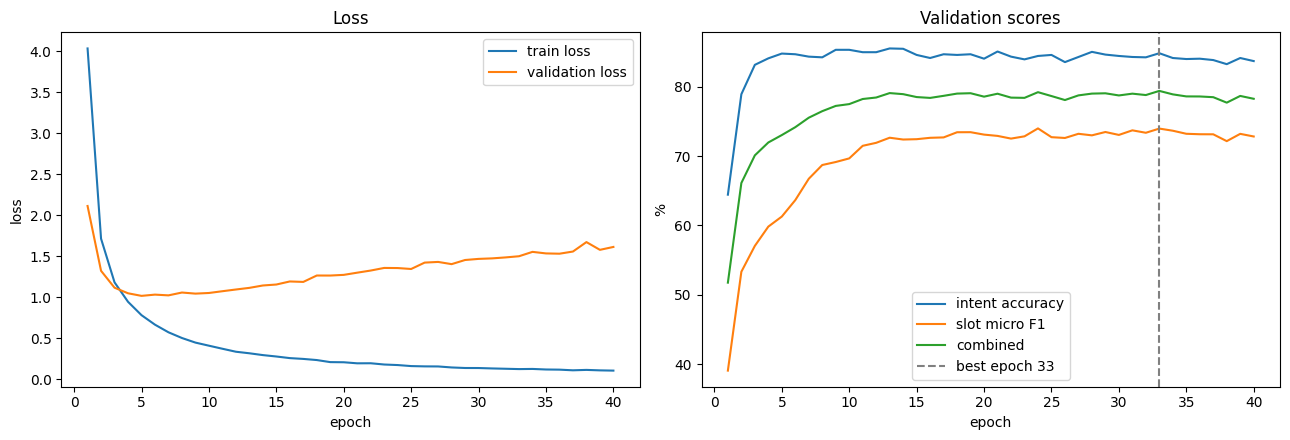

In [12]:
# Per-epoch log and learning curves of the selected configuration
hist = pd.DataFrame(selected["history"])
print(hist.round({"train_loss": 4, "val_loss": 4, "val_intent_acc": 2, "val_slot_f1": 2,
                  "val_combined": 2, "epoch_time_s": 1}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist["epoch"], hist["train_loss"], label="train loss")
axes[0].plot(hist["epoch"], hist["val_loss"], label="validation loss")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].set_title("Loss"); axes[0].legend()
for col, label in [("val_intent_acc", "intent accuracy"), ("val_slot_f1", "slot micro F1"),
                   ("val_combined", "combined")]:
    axes[1].plot(hist["epoch"], hist[col], label=label)
axes[1].axvline(sel_best["epoch"], color="grey", linestyle="--", label=f"best epoch {sel_best['epoch']}")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("%"); axes[1].set_title("Validation scores"); axes[1].legend()
plt.tight_layout(); plt.show()

## Final evaluation of the saved checkpoint

The checkpoint is reloaded from Drive into a fresh model and evaluated without further training. The validation
score must equal the best validation score printed above; the test split is scored once, here.

In [13]:
ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)
assert ckpt["word2id"] == word2id and ckpt["intent2id"] == intent2id and ckpt["slot2id"] == slot2id

final_model = JointTransformer(np.zeros((len(word2id), GLOVE_DIM), dtype=np.float32),
                               len(intent2id), len(slot2id), ckpt["cfg"]).to(device)
final_model.load_state_dict(ckpt["model_state"])
final_total, final_trainable = count_params(final_model)
assert final_total <= 20_000_000

val_res = evaluate(final_model, dev_loader, dev_proc)
test_res = evaluate(final_model, test_loader, test_proc)
print(f"Loaded checkpoint: {CKPT_PATH} (epoch {ckpt['epoch']}, lr {ckpt['cfg']['lr']:.0e}, "
      f"layers {ckpt['cfg']['layers']})")
assert abs(val_res["combined"] - ckpt["val_scores"]["combined"]) < 1e-9, "Reloaded validation score differs"
print("Reloaded validation score matches the best validation score from training.")
print(f"Validation | intent acc: {val_res['intent_acc']:.2f} | slot F1: {val_res['slot_f1']:.2f} | "
      f"combined: {val_res['combined']:.2f}")
print(f"Test       | intent acc: {test_res['intent_acc']:.2f} | slot F1: {test_res['slot_f1']:.2f} | "
      f"combined: {test_res['combined']:.2f}")

print(f"\n{'Model':<18}{'Split':<12}{'Total params':>14}{'Trainable':>12}{'Intent acc':>12}{'Slot F1':>10}{'Epoch':>7}")
for split, res in [("Validation", val_res), ("Test", test_res)]:
    print(f"{'Joint Transformer':<18}{split:<12}{final_total:>14,}{final_trainable:>12,}"
          f"{res['intent_acc']:>12.2f}{res['slot_f1']:>10.2f}{ckpt['epoch']:>7}")

Loaded checkpoint: /content/drive/MyDrive/SC4002/joint_transformer_best.pt (epoch 33, lr 5e-04, layers 1)
Reloaded validation score matches the best validation score from training.
Validation | intent acc: 84.80 | slot F1: 73.95 | combined: 79.38
Test       | intent acc: 83.05 | slot F1: 71.63 | combined: 77.34

Model             Split         Total params   Trainable  Intent acc   Slot F1  Epoch
Joint Transformer Validation       1,792,459   1,792,459       84.80     73.95     33
Joint Transformer Test             1,792,459   1,792,459       83.05     71.63     33
